# 05 · Modelo integrado e impacto financeiro

Este notebook junta as três trilhas num único modelo, com **uma base comum**, e traduz o resultado em reais.

**Base: a posição**, isto é, a pessoa escalada para trabalhar num dia, já descontada a folga semanal da escala atual. Cada trilha vira um multiplicador sobre ela:

| Trilha | Componente | Fórmula (pessoas por posição) |
|---|---|---|
| **T2** | cobertura de ausências | `a / (1 − a)`, em que `a` é a parcela da folha que é cobertura |
| **T3** | mudança de escala | `s (f − 1) / (1 − a)`, em que `s` é a parcela da folha em 6x1 e `f` o fator de folha |
| **T1** | vagas abertas por rotatividade | `T × dias_vaga / 365 × folha`, em que `T` é o turnover anual |

**Folha por posição = (1 + s (f − 1)) / (1 − a) × (1 + T × dias_vaga / 365)**

**Por que isso resolve a inconsistência anterior.** A Trilha 2 media o extra *por posição* (`a / (1 − a)`), e a Trilha 3 multiplicava a *folha inteira*, que já inclui a cobertura. Eram bases diferentes. Aqui as duas partem da posição e o fator da T3 multiplica a folha que contém a cobertura. Para a **operação atual**, a folha F (quadro ativo, que inclui quem está de férias ou afastado) já contém a cobertura: as posições são `F × (1 − a)` e a cobertura dentro da folha é `F × a`. A mudança de escala soma `F × s × (f − 1)`, que não depende de `a`.

**Duas premissas que não vêm dos dados** (e por isso aparecem como parâmetros): 30 dias para repor uma saída, e um multiplicador de 1,7 de encargos sobre o salário. A seção 5 mostra a sensibilidade.

In [1]:
import sys; sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ausencias as au, integrado as ig, rotatividade as rot

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 100)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3})
DIAS_VAGA = 30        # premissa: dias para repor uma saída (não estimável nos dados)
ENCARGOS = 1.7        # premissa da equipe: custo total do empregador / salário (não vem dos dados)

## 1. Insumos (lidos dos resultados das três trilhas)

In [2]:
t1 = pd.read_csv('../resultados/trilha1_projecao.csv').set_index('empresa')
t2 = pd.read_csv('../resultados/trilha2_quadro_extra_por_empresa.csv')
t3 = pd.read_csv('../resultados/trilha3_quadro_adicional.csv')

# T2: perda por ausência a = e / (1 + e), em que e = quadro extra por posição. Média dos 3 anos do contrato.
e = t2.groupby(['empresa', 'cenario']).extra_pct.mean().unstack() / 100
a = e / (1 + e)
F = t2.groupby('empresa').ativos.first()                         # folha = quadro ativo operacional (set/2026)

# T3: fator de folha por cenario de jornada e parcela da folha em 6x1 (populacoes A e B)
ref = t3[(t3.populacao == 'A') & (t3.empresa == 6)].set_index('cenario')
f = (1 + ref.adicional / ref.folha_6x1).to_dict()
folha6 = t3.pivot_table(index='empresa', columns='populacao', values='folha_6x1', aggfunc='first')
s = folha6.div(F, axis=0).fillna(0)

# salario medio de referencia por empresa (ativos operacionais)
rd = lambda n, **k: pd.read_csv(f'../dados/{n}.csv', sep=';', encoding='utf-8-sig', **k)
cad = (rd('dim_integrante', usecols=['ID_INTEGRANTE', 'CODCOLIGADA', 'ID_FUNCAO', 'SALARIO', 'DATAADMISSAO', 'DATADEMISSAO'], parse_dates=['DATAADMISSAO', 'DATADEMISSAO'])
       .merge(rd('dim_funcao', usecols=['ID_FUNCAO', 'FUNCAO']), on='ID_FUNCAO'))
cad = cad[(cad.DATAADMISSAO <= rot.CORTE) & (cad.DATADEMISSAO.isna() | (cad.DATADEMISSAO > rot.CORTE)) & ~cad.FUNCAO.str.upper().str.contains('APRENDIZ')]
sal = cad.groupby('CODCOLIGADA').SALARIO.mean()

emps = [e_ for e_ in F.index if e_ in t1.index and not pd.isna(t1.loc[e_, 'turnover_base_%'])]
ins = pd.DataFrame({'folha (ativos op.)': F, 'a base': a['base'], 'a baixo': a['baixo'], 'a alto': a['alto'],
                    's (A)': s['A'], 's (B)': s['B'], 'turnover base (%)': t1['turnover_base_%'],
                    'turnover alto (%)': t1['contrato_alto_%'], 'salário médio (R$)': sal}).loc[emps]
print('fator de folha por cenário de jornada:', {k: round(v, 3) for k, v in f.items()})
ins.round(3)

fator de folha por cenário de jornada: {'jornada diária mantida': 1.197, 'limite semanal de 40 h': 1.1, 'carga semanal mantida': 1.0}


,folha (ativos op.),a base,a baixo,a alto,s (A),s (B),turnover base (%),turnover alto (%),salário médio (R$)
3,113.0,0.138,0.124,0.153,0.000,0.000,32.81,41.12,5150.487
4,7.0,0.234,0.224,0.244,0.143,0.143,27.00,46.36,8959.410
5,2824.0,0.178,0.161,0.193,0.000,0.418,10.20,12.75,2884.396
6,760.0,0.155,0.138,0.174,0.834,0.834,61.08,71.04,1924.545
7,45.0,0.250,0.200,0.302,0.667,0.667,13.62,24.47,2242.484
8,978.0,0.166,0.150,0.180,0.072,0.825,28.48,34.53,1780.532


Todas as entradas vêm dos CSVs que as trilhas geraram, então o modelo integrado se atualiza se uma trilha mudar:

- **a (T2):** o quadro extra por posição do cenário base (média dos 3 anos), convertido em `a = e / (1 + e)`. Também lemos os cenários baixo e alto.
- **F:** o quadro ativo operacional de set/2026 (sem aprendizes), que é a folha.
- **s e f (T3):** a parcela da folha em 6x1 (população A: 6x1 no cadastro; B: inclui jornada mensal e revezamento) e o fator de folha por cenário de jornada.
- **T (T1):** o turnover base e o limite alto da faixa do contrato.
- **Salário:** a média do **salário de referência** do cadastro, por empresa. É um valor de referência por função, não o custo real efetivo.

- **Erro de extrapolação da T2** (backtest do notebook 03): 5,4 p.p. de perda, aplicado só à parcela da folha de cada empresa que **não tem dado próprio** (empresa 5: 100%; 8: 82%; 7: 68%; 6: 17%).

## 2. Folha por posição: um multiplicador, três componentes

In [3]:
def comp(emp, a_=None, s_pop='A', f_cen='jornada diária mantida', T=None, dias=DIAS_VAGA):
    return ig.multiplicadores(a['base'][emp] if a_ is None else a_, s[s_pop][emp], f[f_cen],
                              t1.loc[emp, 'turnover_base_%'] if T is None else T, dias)

tabA = pd.DataFrame({emp: comp(emp) for emp in emps}).T * 100
tabB = pd.DataFrame({emp: comp(emp, s_pop='B') for emp in emps}).T * 100
print('Pessoas na folha para cada 100 posições (população A: 6x1 no cadastro; jornada diária mantida)')
tabA.round(1)

Pessoas na folha para cada 100 posições (população A: 6x1 no cadastro; jornada diária mantida)


,posições,cobertura (T2),escala (T3),vagas (T1),total
3,100.0,16.0,0.0,3.1,119.2
4,100.0,30.5,3.7,3.0,137.2
5,100.0,21.6,0.0,1.0,122.7
6,100.0,18.4,19.4,6.9,144.8
7,100.0,33.4,17.5,1.7,152.6
8,100.0,19.9,1.7,2.8,124.4


**População A, jornada diária mantida.** Para cada 100 posições, a folha tem de ter:

| Empresa | Cobertura (T2) | Escala (T3) | Vagas (T1) | **Total** |
|---|---|---|---|---|
| 5 | 21,6 | 0,0 | 1,0 | **122,7** |
| 8 | 19,9 | 1,7 | 2,8 | **124,4** |
| 6 | 18,4 | 19,4 | 6,9 | **144,8** |
| 7 | 33,4 | 17,5 | 1,7 | 152,6 |
| 3 | 16,0 | 0,0 | 3,1 | 119,2 |
| 4 | 30,5 | 3,7 | 3,0 | 137,2 |

A cobertura é a parcela mais estável (16% a 33%). A escala só pesa onde há 6x1 no cadastro: **a empresa 6 sai de 118 para 145 pessoas por 100 posições, sendo 18 de cobertura, 19 da mudança de escala e 7 de vagas.** As vagas são pessoas a mais para manter o serviço enquanto uma saída não foi reposta (premissa de 30 dias).

As empresas 4 (7 pessoas) e 7 (45) têm amostra pequena; os números delas são indicativos.

In [4]:
print('Mesma conta com a população B (inclui jornada mensal e revezamento como 6x1)')
tabB.round(1)

Mesma conta com a população B (inclui jornada mensal e revezamento como 6x1)


,posições,cobertura (T2),escala (T3),vagas (T1),total
3,100.0,16.0,0.0,3.1,119.2
4,100.0,30.5,3.7,3.0,137.2
5,100.0,21.6,10.0,1.1,132.8
6,100.0,18.4,19.4,6.9,144.8
7,100.0,33.4,17.5,1.7,152.6
8,100.0,19.9,19.5,3.3,142.6


**População B.** Se as tripulações de jornada mensal (empresa 5) e de revezamento (empresa 8) operarem em 6x1, a empresa 5 sobe de 123 para **133** pessoas por 100 posições e a empresa 8, de 124 para **142**. As outras não mudam. Essa diferença é a incerteza sobre a escala real dessas tripulações, e não uma incerteza estatística.

## 3. A operação atual em pessoas

In [5]:
atual = pd.DataFrame({emp: ig.operacao_atual(F[emp], a['base'][emp], s['A'][emp], f['jornada diária mantida'], t1.loc[emp, 'turnover_base_%'], DIAS_VAGA)
                      for emp in emps}).T
atual['folha atual'] = F.loc[emps]
atual.loc['total'] = atual.sum()
atual.round(0)

,posições,cobertura (T2),escala (T3),vagas (T1),total,folha atual
3,97.0,16.0,0.0,3.0,116.0,113.0
4,5.0,2.0,0.0,0.0,7.0,7.0
5,2321.0,503.0,0.0,24.0,2848.0,2824.0
6,642.0,118.0,125.0,44.0,929.0,760.0
7,34.0,11.0,6.0,1.0,51.0,45.0
8,816.0,162.0,14.0,23.0,1015.0,978.0
total,3916.0,811.0,145.0,95.0,4967.0,4727.0


Aplicando o modelo à operação atual, a folha de 4.727 pessoas se decompõe em **3.916 posições + 811 de cobertura de ausências**. Com a mudança de escala (população A, jornada diária mantida) e as vagas por rotatividade, a folha necessária passa a **4.967: +145 pela escala e +95 pelas vagas, ou seja, +240 (+5,1%)**.

A empresa 5 concentra a maior parte da folha (2.848 de 4.967) e quase não muda (+24, só vagas), porque nenhuma pessoa dela está em 6x1 no cadastro (população A). A empresa 6 é a que mais muda: de 760 para 929 (+22%).

In [6]:
# reconciliacao com as notebooks anteriores
rec = pd.DataFrame({'T2 reportada (ativos × e)': F.loc[emps] * e['base'].loc[emps],
                    'T2 integrada (folha × a)': F.loc[emps] * a['base'].loc[emps],
                    'T3 (A, diária mantida)': [F[x] * s['A'][x] * (f['jornada diária mantida'] - 1) for x in emps]})
rec.loc['total'] = rec.sum()
rec.round(0)

,T2 reportada (ativos × e),T2 integrada (folha × a),"T3 (A, diária mantida)"
empresa,,,
3,18.0,16.0,0.0
4,2.0,2.0,0.0
5,611.0,503.0,0.0
6,140.0,118.0,125.0
7,15.0,11.0,6.0
8,194.0,162.0,14.0
total,981.0,811.0,145.0


**Reconciliação com os notebooks anteriores.** A Trilha 3 não muda: 145 integrantes. A Trilha 2 muda de **975 para 811** em número de pessoas. O que mudou foi só a **base** de contagem, e não o método:

- No notebook 03, o extra por posição (`e`) foi multiplicado pelo quadro ativo, tratando-o como *posições*: 975.
- Aqui, o quadro ativo é tratado como a *folha*, que já contém a cobertura: `F × a` = 811.

O percentual por posição da Trilha 2 (por exemplo, 21,6% na empresa 5) continua válido e é a medida que se aplica a uma licitação. A leitura adotada neste modelo é a que combina com a Trilha 3, e por isso passa a ser a de referência em pessoas.

## 4. De onde vem a incerteza

In [7]:
def total(emp, **k): return comp(emp, **k)['total'] * 100

# erro de extrapolacao da T2 (backtest, notebook 03): vale para a parcela da folha de cada empresa SEM dado proprio
cel2 = pd.read_csv('../resultados/trilha2_quadro_extra_por_celula.csv')
cel2 = cel2[(cel2.cenario == 'base') & (cel2.ano == 1)]
sem_dado = (cel2.assign(p=cel2.ativos * (1 - cel2.peso_dados)).groupby('empresa').p.sum() / cel2.groupby('empresa').ativos.sum())
RMSE = pd.read_csv('../resultados/trilha2_erro_extrapolacao.csv').rmse_pp.iloc[0] / 100
ext = (RMSE * sem_dado).reindex(emps)
print(f'erro de extrapolação da T2: {RMSE*100:.1f} p.p. de perda; parcela da folha sem dado próprio por empresa:', sem_dado.round(2).to_dict())
linhas = []
for emp in emps:
    base = total(emp)
    linhas.append({'empresa': emp, 'base (por 100 posições)': base,
        'a (T2): baixo': total(emp, a_=a['baixo'][emp]) - base, 'a (T2): alto': total(emp, a_=a['alto'][emp]) - base,
        'a (T2): extrapolação −1σ': total(emp, a_=a['base'][emp] - ext[emp]) - base, 'a (T2): extrapolação +1σ': total(emp, a_=a['base'][emp] + ext[emp]) - base,
        'turnover (T1): alto': total(emp, T=t1.loc[emp, 'contrato_alto_%']) - base,
        'população 6x1: B em vez de A': total(emp, s_pop='B') - base,
        'jornada: 40 h': total(emp, f_cen='limite semanal de 40 h') - base,
        'jornada: carga semanal mantida': total(emp, f_cen='carga semanal mantida') - base,
        'prazo de reposição: 15 dias': total(emp, dias=15) - base, 'prazo de reposição: 60 dias': total(emp, dias=60) - base})
torn = pd.DataFrame(linhas).set_index('empresa')
torn.round(1)

erro de extrapolação da T2: 5.4 p.p. de perda; parcela da folha sem dado próprio por empresa: {3: 0.5, 4: 0.94, 5: 1.0, 6: 0.17, 7: 0.68, 8: 0.82}


,base (por 100 posições),a (T2): baixo,a (T2): alto,a (T2): extrapolação −1σ,a (T2): extrapolação +1σ,turnover (T1): alto,população 6x1: B em vez de A,jornada: 40 h,jornada: carga semanal mantida,prazo de reposição: 15 dias,prazo de reposição: 60 dias
empresa,,,,,,,,,,,
3,119.2,-2.0,2.0,-3.7,3.9,0.8,0.0,0.0,0.0,-1.6,3.1
4,137.2,-1.7,1.8,-8.6,9.8,2.1,0.0,-1.8,-3.8,-1.5,3.0
5,122.7,-2.4,2.4,-7.6,8.7,0.3,10.1,-0.0,-0.0,-0.5,1.0
6,144.8,-2.9,3.3,-1.6,1.6,1.1,0.0,-10.0,-20.4,-3.5,6.9
7,152.6,-9.6,11.3,-7.2,7.9,1.3,0.0,-8.7,-17.7,-0.8,1.7
8,124.4,-2.3,2.2,-6.3,7.0,0.6,18.2,-0.9,-1.7,-1.4,2.8


Cada coluna muda **uma** premissa por vez e mostra quantas pessoas por 100 posições o total se desloca em relação ao caso base:

- **População 6x1 (A para B):** +10,1 na empresa 5 e +18,1 na empresa 8. É a escala real das tripulações, que os dados não informam.
- **Jornada pós-mudança:** na empresa 6, de −10,0 (limite de 40 h) a −20,4 (carga semanal mantida). É uma definição de contrato.
- **Cobertura de ausências (T2), erro de extrapolação:** de −7,6 a +8,7 na empresa 5, −6,3 a +7,0 na 8 e −7,2 a +7,9 na 7. Na empresa 6, que tem dado próprio, é só ±1,6. Vem do backtest (notebook 03).
- **Cobertura de ausências (T2), faixa de cenários:** ±2 a ±3 nas empresas grandes. É menor que o erro de extrapolação, que é o número mais honesto para as empresas sem dado.
- **Prazo de reposição (15 a 60 dias):** de −3,5 a +6,9 na empresa 6. É premissa.
- **Rotatividade (T1, limite alto):** no máximo +2,1.

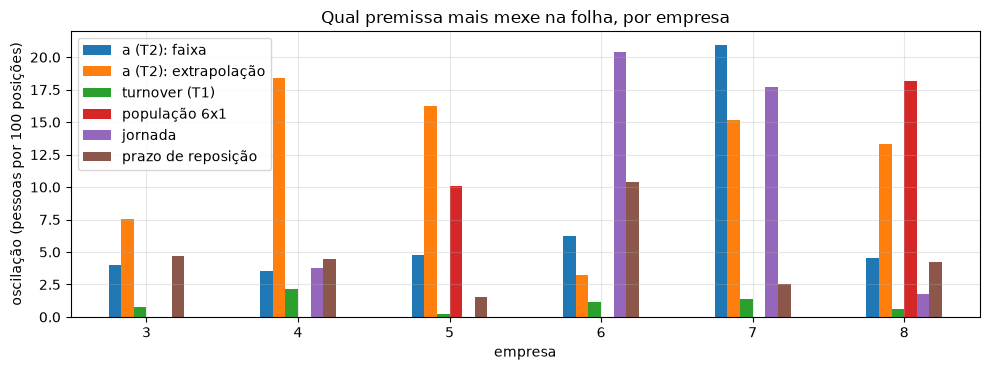

In [8]:
fatores = ['a (T2): faixa', 'a (T2): extrapolação', 'turnover (T1)', 'população 6x1', 'jornada', 'prazo de reposição']
oscil = pd.DataFrame({
    'a (T2): faixa': torn['a (T2): alto'] - torn['a (T2): baixo'],
    'a (T2): extrapolação': torn['a (T2): extrapolação +1σ'] - torn['a (T2): extrapolação −1σ'],
    'turnover (T1)': torn['turnover (T1): alto'].abs(),
    'população 6x1': torn['população 6x1: B em vez de A'].abs(),
    'jornada': torn['jornada: carga semanal mantida'].abs(),
    'prazo de reposição': torn['prazo de reposição: 60 dias'] - torn['prazo de reposição: 15 dias']})
ax = oscil[fatores].plot(kind='bar', stacked=False, figsize=(10, 3.8))
ax.set_ylabel('oscilação (pessoas por 100 posições)'); ax.set_xlabel('empresa'); ax.set_title('Qual premissa mais mexe na folha, por empresa')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

O gráfico mostra que a fonte dominante de incerteza **depende da empresa**:

- **Empresa 6** (dado próprio): domina a **jornada** pós-mudança (até −20 pessoas por 100 posições). A estimação estatística pesa pouco.
- **Empresas 5 e 8** (sem dado próprio em grande parte): três fontes de ordem parecida, a **escala real das tripulações** (+10 e +18), o **erro de extrapolação das taxas de ausência** (±8 e ±7) e, na 8, a população 6x1.
- **Empresa 7** (45 pessoas): amostra pequena, com a faixa de ausência e o erro de extrapolação de ±8 a ±10.

Em resumo, a maior parte da incerteza vem de informação que a SIAN tem e nós não: o **ponto da empresa 5**, a **escala real das tripulações** e a **jornada** que valerá após a mudança.

## 5. Impacto em R$

In [9]:
# custo anual da operação atual (R$ milhões), por componente; salário de referência médio da empresa
def milhoes(x): return x / 1e6
linhas = []
for emp in emps:
    pess = atual.loc[emp]
    for enc, rot_enc in ((1.0, 'só salário'), (ENCARGOS, f'com encargos (×{ENCARGOS})')):
        linhas.append({'empresa': emp, 'custo': rot_enc, **{k: milhoes(ig.custo_anual(pess[k], sal[emp], enc)) for k in ['posições', 'cobertura (T2)', 'escala (T3)', 'vagas (T1)']}})
cus = pd.DataFrame(linhas)
cus['total'] = cus[['posições', 'cobertura (T2)', 'escala (T3)', 'vagas (T1)']].sum(axis=1)
sem = cus[cus.custo == 'só salário'].set_index('empresa').drop(columns='custo')
sem.loc['total'] = sem.sum()
sem.round(2)

,posições,cobertura (T2),escala (T3),vagas (T1),total
empresa,,,,,
3,6.02,0.96,0.00,0.19,7.17
4,0.58,0.18,0.02,0.02,0.79
5,80.35,17.39,0.01,0.82,98.57
6,14.82,2.73,2.88,1.03,21.46
7,0.91,0.30,0.16,0.02,1.39
8,17.43,3.47,0.29,0.50,21.69
total,120.11,25.03,3.36,2.56,151.07


Custo anual da operação atual por componente, usando o salário médio de referência de cada empresa. **Só salário** (sem encargos), em R$ milhões por ano: total de **R$ 151,1 milhões**, dos quais posições 120,1, cobertura de ausências 25,0, mudança de escala 3,4 e vagas 2,6. A empresa 5 responde por R$ 98,6 milhões (65%), e é a de dados menos confiáveis.

Com o multiplicador de encargos de 1,7 (premissa da equipe), o total é de **R$ 256,8 milhões por ano**: posições 204,2, cobertura 42,6, escala 5,7 e vagas 4,4.

In [10]:
com = cus[cus.custo != 'só salário'].set_index('empresa').drop(columns='custo'); com.loc['total'] = com.sum()
print(f'Com encargos (×{ENCARGOS}, premissa), R$ milhões por ano'); com.round(2)

Com encargos (×1.7, premissa), R$ milhões por ano


,posições,cobertura (T2),escala (T3),vagas (T1),total
empresa,,,,,
3,10.23,1.64,0.00,0.32,12.19
4,0.98,0.30,0.04,0.03,1.34
5,136.60,29.57,0.01,1.39,167.57
6,25.20,4.64,4.90,1.74,36.48
7,1.54,0.52,0.27,0.03,2.35
8,29.63,5.89,0.50,0.84,36.87
total,204.19,42.56,5.72,4.36,256.81


In [11]:
# contrato de 3 anos (valores constantes), custo adicional frente a "so posicoes", e quanto cada trilha pesa
tot = com.loc['total']
resumo = pd.DataFrame({'R$ milhões/ano': tot, 'R$ milhões em 3 anos': tot * 3, '% do custo das posições': tot / tot['posições'] * 100}).round(1)
resumo

,R$ milhões/ano,R$ milhões em 3 anos,% do custo das posições
posições,204.2,612.6,100.0
cobertura (T2),42.6,127.7,20.8
escala (T3),5.7,17.2,2.8
vagas (T1),4.4,13.1,2.1
total,256.8,770.4,125.8


**Atenção à leitura.** O "custo acima das posições" **não é** o aumento de custo em relação à operação de hoje: a cobertura de ausências (T2) já existe e já é paga na folha atual (são os ~811 integrantes que cobrem férias e afastamentos dentro dos 4.727). O que é **novo** em relação à folha atual é só a mudança de escala (T3) e as vagas por rotatividade (T1):

In [12]:
# acrescimo sobre a folha atual: a cobertura (T2) ja esta dentro da folha de hoje
novos = ['escala (T3)', 'vagas (T1)']
acr = pd.DataFrame({'pessoas': atual.loc[list(emps), novos].sum(),
                    'R$ mi/ano (só salário)': sem.loc['total', novos],
                    f'R$ mi/ano (encargos ×{ENCARGOS})': com.loc['total', novos]})
acr.loc['total'] = acr.sum()
acr[f'R$ mi em 3 anos (encargos ×{ENCARGOS})'] = acr[f'R$ mi/ano (encargos ×{ENCARGOS})'] * 3
acr[f'% da folha atual (encargos ×{ENCARGOS})'] = acr[f'R$ mi/ano (encargos ×{ENCARGOS})'] / (com.loc['total', ['posições', 'cobertura (T2)']].sum()) * 100
acr.round(2).to_csv('../resultados/integrado_acrescimo_folha_atual.csv', encoding='utf-8-sig')
acr.round(1)

,pessoas,R$ mi/ano (só salário),R$ mi/ano (encargos ×1.7),R$ mi em 3 anos (encargos ×1.7),% da folha atual (encargos ×1.7)
escala (T3),144.8,3.4,5.7,17.2,2.3
vagas (T1),95.1,2.6,4.4,13.1,1.8
total,239.9,5.9,10.1,30.2,4.1


Em um contrato de 3 anos a valores constantes (sem reajuste, sem inflação e sem crescimento de quadro), com encargos de 1,7:

- A **cobertura de ausências** custa **R$ 128 milhões** (20,8% do custo das posições). É o componente que mais pesa.
- A **mudança de escala** (população A, jornada diária mantida) custa **R$ 17 milhões** (2,8%).
- As **vagas por rotatividade** custam **R$ 13 milhões** (2,1%).
- Os três juntos somam cerca de **R$ 158 milhões** acima do custo das posições, ou 25,8%. **Isso não é o aumento sobre a folha atual:** a cobertura já existe e já é paga hoje. O acréscimo real sobre a folha atual é só escala + vagas: **+240 pessoas, cerca de R$ 10 milhões por ano ou R$ 30 milhões em 3 anos** (4,1% da folha atual, com encargos de 1,7).

A mudança de escala é pequena **na população A** (porque só 736 pessoas estão em 6x1 no cadastro). Na população B ela cresce bastante, e é o maior risco do resultado.

In [13]:
# reposicao de saidas (premissa de 1 salario por saida): custo anual de admissao e treinamento, fora do headcount
saidas = pd.Series({emp: atual.loc[emp, 'total'] * t1.loc[emp, 'turnover_base_%'] / 100 for emp in emps})
rep = pd.DataFrame({'saídas por ano': saidas, 'custo de reposição (R$ mi/ano, 1 salário por saída)': saidas * sal[emps] / 1e6})
rep.loc['total'] = rep.sum(); rep.round(2)

,saídas por ano,"custo de reposição (R$ mi/ano, 1 salário por saída)"
3,38.08,0.20
4,1.99,0.02
5,290.48,0.84
6,567.55,1.09
7,7.01,0.02
8,289.07,0.51
total,1194.18,2.67


**Reposição de saídas.** A operação gera cerca de 1.194 saídas por ano. Com a premissa de um salário de custo por saída (recrutamento e treinamento, valor nosso), são **R$ 2,7 milhões por ano**, pequeno frente à folha. A rotatividade pesa mais pelas vagas em aberto (seção 3) que pelo custo de reposição direto, sob essa premissa.

In [14]:
# sensibilidade ao multiplicador de encargos (custo total das tres trilhas, R$ milhões por ano)
extra = sem.loc['total', ['cobertura (T2)', 'escala (T3)', 'vagas (T1)']].sum()
pd.DataFrame({f'encargos ×{x}': {'custo adicional (T1+T2+T3), R$ mi/ano': extra * x} for x in (1.0, 1.5, 1.7, 2.0)}).round(1)

,encargos ×1.0,encargos ×1.5,encargos ×1.7,encargos ×2.0
"custo adicional (T1+T2+T3), R$ mi/ano",31.0,46.4,52.6,61.9


In [15]:
# custo da incerteza de extrapolacao (R$ milhoes por ano, com encargos): oscilacao do total por posicao x posicoes x salario
linhas = []
for emp in emps:
    posicoes = F[emp] * (1 - a['base'][emp])
    for lado, col in (('−1σ', 'a (T2): extrapolação −1σ'), ('+1σ', 'a (T2): extrapolação +1σ')):
        linhas.append({'empresa': emp, 'lado': lado, 'R$ mi/ano': ig.custo_anual(posicoes * torn.loc[emp, col] / 100, sal[emp], ENCARGOS) / 1e6})
pd.DataFrame(linhas).pivot(index='empresa', columns='lado', values='R$ mi/ano').round(1)

lado,+1σ,−1σ
empresa,,
3,0.4,-0.4
4,0.1,-0.1
5,11.8,-10.4
6,0.4,-0.4
7,0.1,-0.1
8,2.1,-1.9


O erro de extrapolação, que é o maior componente estatístico, custa aproximadamente **±R$ 11 milhões por ano** (com encargos) na empresa 5 e **±R$ 2 milhões** na empresa 8. Esse é o valor que o ponto da empresa 5 removeria. É grande frente ao custo de reposição direto (R$ 2,7 milhões por ano), e é a razão de pedir esse dado à organização.

## 6. Limitações

- **A folha atual é tratada como adequadamente dimensionada.** O modelo supõe que o quadro ativo já cobre as ausências (posições = F × (1 − a)). Se a operação atual estiver sub ou superdimensionada, as posições reais diferem.
- **Salário de referência, não custo real.** O cadastro traz um salário de referência por função. Encargos (1,7), 13º, benefícios e horas extras estão no multiplicador, que é premissa, não dado. A seção 5 mostra a sensibilidade.
- **A empresa 5 domina o custo** (65% do salário) e é a de menor confiança (sem ponto próprio).
- **Valores constantes por 3 anos.** Sem reajuste, sem crescimento de quadro e sem a mudança de composição que a Trilha 1 sugere (empresa 6 em expansão).
- **Vagas como reserva de pessoas.** Tratar as vagas abertas como pessoas extras supõe que a empresa mantém uma reserva. É premissa, com 30 dias para repor uma saída.
- **Componentes combinados de forma simples.** A cobertura, a escala e a rotatividade se multiplicam sem considerar interações entre elas (por exemplo, a mudança de escala alterar as ausências ou a rotatividade).
- **Escala e jornada.** O resultado da mudança de escala depende de uma decisão de contrato (jornada) e de informação (escala real das tripulações) que não estão nos dados.

- **Incerteza de extrapolação.** O erro de 5,4 p.p. de perda vem de 4 células (uma delas, a empresa 3, muito diferente das outras). Com amostra tão pequena, é uma estimativa grosseira e pode estar subestimada ou superestimada.

In [16]:
import os; os.makedirs('../resultados', exist_ok=True)
pd.concat({'por_100_posicoes_A': tabA, 'por_100_posicoes_B': tabB}, names=['populacao', 'empresa']).round(3).to_csv('../resultados/integrado_por_100_posicoes.csv', encoding='utf-8-sig')
atual.round(2).to_csv('../resultados/integrado_operacao_atual_pessoas.csv', encoding='utf-8-sig')
cus.round(3).to_csv('../resultados/integrado_custos.csv', index=False, encoding='utf-8-sig')
torn.round(3).to_csv('../resultados/integrado_sensibilidade.csv', encoding='utf-8-sig')